# MileStone 2 Project: Decomposing Paired-Rating Disagreement
## Part B: Unsupervised Learning
1. Load the Fixed Training/Holdout Split
2. Create Seven-Dimensional Disagreement Profiles
3. Analyze the Full Training Sample
4. Analyze Disagreement-Only Essays
5. Evaluate K-Means Stability, Select k = 4, and Interpret Profiles
6. Unsupervised Evaluation Summary and Visualizations
    - PCA Evaluation and Visualizations
    - K-Means Evaluation and Visualizations
    - K-Means Stability Summary and Visualization
7. Holdout/Test Data Replication
8. Additional Exploratory Analysis: Association between Rater-Pair and Profiles 

## Stage 0: Load the Original 3,510 / 2,330 Split
- The origial data file has the `set` column for spliting train and test.

In [1]:
## Read in packages
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedKFold, GroupKFold, cross_validate, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    roc_auc_score, precision_recall_curve, auc,
    balanced_accuracy_score, f1_score, confusion_matrix,
    silhouette_score, adjusted_rand_score
)
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import TfidfVectorizer

RANDOM_STATE = 589  # For the purpose of reproducibility
N_JOBS = -1         # Use all available CPU cores

In [2]:
# Creating results drive
RESULTS_DIR = Path(r'C:/Users/USEO9DA/0_MyStuff/M2/results')

# Read-in the original data file, which includes the set column
DATA_PATH = Path(r'C:\Users\USEO9DA\0_MyStuff\M2\Data\0922_Final_Clean_Merged.csv')
SET_COL = 'set'
TRAIN_LABEL = 'train'
HOLDOUT_LABEL = 'test'

# Loads the dataset based on file type
def read_table(path):
    suffix = path.suffix.lower()
    if suffix == '.csv':
        return pd.read_csv(path)
    if suffix in {'.xlsx', '.xls'}:
        return pd.read_excel(path)
    raise ValueError(
        f'Unsupported file type: {path.suffix}'
    )

df = read_table(DATA_PATH)

# Checking whether the split column exists
if SET_COL not in df.columns:
    raise ValueError(f"Split column '{SET_COL}' not found.")

# Standardizing the split labels for matching
split_values = (df[SET_COL].astype(str).str.strip().str.lower())

# Defining training and holdout/test samples
train_df = df[split_values == TRAIN_LABEL.lower()].copy()
holdout_df = df[split_values == HOLDOUT_LABEL.lower()].copy()

# Confirming the locked sample sizes
print('Full sample :', df.shape)
print('Training    :', train_df.shape)
print('Holdout     :', holdout_df.shape)

Full sample : (5840, 75)
Training    : (3510, 75)
Holdout     : (2330, 75)


## Stage 1: Create Seven Disagreement Profiles
- Created by the seven `Delta_*` variables.

In [3]:
# Creating the seven absolute disagreement (Delta) variables
DIMS = ['Overall','Cohesion','Syntax','Vocabulary','Phraseology','Grammar','Conventions']

# Checking whether all paired-rating columns are present
required = [f'{d}_{r}' for d in DIMS for r in (1, 2)]
missing = [c for c in required if c not in train_df.columns]
if missing:
    raise ValueError(f'Missing rating columns: {missing}')

# Creating absolute differences between the two raters
for d in DIMS:
    train_df[f'Delta_{d}'] = (train_df[f'{d}_2'] - train_df[f'{d}_1']).abs()
    holdout_df[f'Delta_{d}'] = (holdout_df[f'{d}_2'] - holdout_df[f'{d}_1']).abs()

# Defining the seven disagreement-profile columns
DELTA_COLS = [f'Delta_{d}' for d in DIMS]
X_train_profile = train_df[DELTA_COLS].copy()
X_holdout_profile = holdout_df[DELTA_COLS].copy()
print(X_train_profile.shape, X_holdout_profile.shape)

# Displaying
display(X_train_profile.describe())

(3510, 7) (2330, 7)


,Delta_Overall,Delta_Cohesion,Delta_Syntax,Delta_Vocabulary,Delta_Phraseology,Delta_Grammar,Delta_Conventions
count,3510.000000,3510.000000,3510.000000,3510.000000,3510.000000,3510.000000,3510.000000
mean,0.394017,0.510256,0.470655,0.426496,0.467521,0.492877,0.471225
std,0.489291,0.522814,0.505450,0.500366,0.509191,0.516836,0.513315
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
max,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000


## Stage 2A: Run PCA on the Full Training Sample
- PCA is fitted on the 3,510 training sample.

In [4]:
# Conducting PCA Analysis
pca_full=PCA()
train_pca_full=pca_full.fit_transform(X_train_profile)
pca_full_summary=pd.DataFrame({
    'component':[f'PC{i+1}' for i in range(len(DELTA_COLS))],
    'explained_variance_ratio':pca_full.explained_variance_ratio_,
    'cumulative_explained_variance':np.cumsum(pca_full.explained_variance_ratio_)})
pca_full_loadings=pd.DataFrame(pca_full.components_.T,index=DELTA_COLS,columns=[f'PC{i+1}' for i in range(len(DELTA_COLS))])

# Displying summary and loadings
print('=' * 70)
print('PCA Summary: Disagreement-Only Sample')
print('=' * 70)
display(pca_full_summary)
print('=' * 70)
print('PCA Loadings: Disagreement-Only Sample')
print('=' * 70)
display(pca_full_loadings)

# Saving the summary results
output_file = RESULTS_DIR / 'pca_full_summary.csv'
pca_full_summary.to_csv(output_file,index=False)
print(f"Saved to: {output_file}")
# Saving the laoding results
output_file = RESULTS_DIR / 'pca_full_loadings.csv'
pca_full_loadings.to_csv(output_file,index=False)
print(f"Saved to: {output_file}")

PCA Summary: Disagreement-Only Sample


,component,explained_variance_ratio,cumulative_explained_variance
0,PC1,0.191660,0.191660
1,PC2,0.149626,0.341286
2,PC3,0.148455,0.489741
3,PC4,0.142389,0.632129
4,PC5,0.137630,0.769759
5,PC6,0.129183,0.898942
6,PC7,0.101058,1.000000


PCA Loadings: Disagreement-Only Sample


,PC1,PC2,PC3,PC4,PC5,PC6,PC7
Delta_Overall,0.580063,0.062391,0.001814,-0.099498,0.047046,0.074908,0.801191
Delta_Cohesion,0.483410,-0.314341,0.236317,0.638144,0.198476,-0.336947,-0.226948
Delta_Syntax,0.331349,0.322242,-0.150477,-0.394907,0.695115,-0.032512,-0.351470
Delta_Vocabulary,0.291418,-0.386006,-0.352109,0.061643,-0.086201,0.757693,-0.238254
Delta_Phraseology,0.361725,-0.247136,-0.226013,-0.476782,-0.514514,-0.461492,-0.227982
Delta_Grammar,0.271325,0.763498,-0.114338,0.322791,-0.421179,0.094516,-0.199655
Delta_Conventions,0.175108,0.021235,0.856372,-0.302666,-0.160194,0.289468,-0.185616


Saved to: C:\Users\USEO9DA\0_MyStuff\M2\results\pca_full_summary.csv
Saved to: C:\Users\USEO9DA\0_MyStuff\M2\results\pca_full_loadings.csv


## Stage 2B: Run K-means on the Full Training Profiles
- Runs K-means clustering for k = 2 through k = 8

In [5]:
# Conducting K-means analysis
K_VALUES=range(2,9)
full_kmeans_models={}
rows=[]
for k in K_VALUES:
    km=KMeans(n_clusters=k,n_init=50,random_state=RANDOM_STATE)
    labels=km.fit_predict(X_train_profile)
    full_kmeans_models[k]=km
    counts=pd.Series(labels).value_counts()
    rows.append({'k':k,'silhouette':silhouette_score(X_train_profile,labels),
                 'min_cluster_n':counts.min(),'max_cluster_n':counts.max()})
full_kmeans_eval=pd.DataFrame(rows)

#Displaying the results
display(full_kmeans_eval)

# Saving the results 
output_file = RESULTS_DIR / 'full_kmeans_eval.csv'
full_kmeans_eval.to_csv(output_file,index=False)
print(f"Saved to: {output_file}")

  File "C:\Users\USEO9DA\AppData\Roaming\Python\Python39\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
  File "C:\Users\USEO9DA\.conda\envs\ai_chat\lib\subprocess.py", line 505, in run
    with Popen(*popenargs, **kwargs) as process:
  File "C:\Users\USEO9DA\.conda\envs\ai_chat\lib\subprocess.py", line 951, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\USEO9DA\.conda\envs\ai_chat\lib\subprocess.py", line 1436, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,


,k,silhouette,min_cluster_n,max_cluster_n
0,2,0.153164,1750,1760
1,3,0.144351,941,1356
2,4,0.168339,801,969
3,5,0.145158,497,846
4,6,0.149173,500,692
5,7,0.163198,404,676
6,8,0.161303,267,512


Saved to: C:\Users\USEO9DA\0_MyStuff\M2\results\full_kmeans_eval.csv


## Stage 3: Repeat PCA and K-means for the Disagreement-only Sample
- Exclude essays with complete agreement across all seven dimensions.
- The essay has at least one rater disagreement.

In [6]:
# Checking whether the sum of the seven disagreement values is greater than 0
    # The essay should have at least one rater disagreement.
train_disagree_mask = X_train_profile.sum(axis=1) > 0
holdout_disagree_mask = X_holdout_profile.sum(axis=1) > 0

# Creating disagreement-only datasets
X_train_disagree = X_train_profile.loc[train_disagree_mask].copy()
X_holdout_disagree = X_holdout_profile.loc[holdout_disagree_mask].copy()
print('Train disagreement-only:',len(X_train_disagree))
print('Holdout disagreement-only:',len(X_holdout_disagree))

# Fitting the PCA using the disagreement-onlytraining sample.
pca_disagree=PCA()
train_pca_disagree=pca_disagree.fit_transform(X_train_disagree)
# Createing a table of variance explained by each principal component
pca_disagree_summary=pd.DataFrame({
    'component':[f'PC{i+1}' for i in range(len(DELTA_COLS))],
    'explained_variance_ratio':pca_disagree.explained_variance_ratio_,
    'cumulative_explained_variance':np.cumsum(pca_disagree.explained_variance_ratio_)
})

# Creating a loading table of each principal component for each disgreement dimension
pca_disagree_loadings=pd.DataFrame(
    pca_disagree.components_.T,index=DELTA_COLS,
    columns=[f'PC{i+1}' for i in range(len(DELTA_COLS))]
)

# Displaying the PCA results
print('=' * 70)
print('PCA Summary: Disagreement-Only Sample')
print('=' * 70)
display(pca_disagree_summary)
print('=' * 70)
print('PCA Loadings: Disagreement-Only Sample')
print('=' * 70)
display(pca_disagree_loadings)

# Saving the PCA Summary Results
output_file = RESULTS_DIR / 'pca_disagree_summary.csv'
pca_disagree_summary.to_csv(output_file,index=False)
print(f"Saved to: {output_file}")
# Saving the PCA loading Results
output_file = RESULTS_DIR / 'pca_disagree_loadings.csv'
pca_disagree_loadings.to_csv(output_file,index=False)
print(f"Saved to: {output_file}")


# Conducting K-means for comparing different numbers of disagreement profiles
rows=[]; disagree_kmeans_models={}
# Trying each candidate number of clusters defined in K_VALUES
for k in K_VALUES:
    km=KMeans(n_clusters=k,n_init=50,random_state=RANDOM_STATE)
    labels=km.fit_predict(X_train_disagree)
    disagree_kmeans_models[k]=km
    counts=pd.Series(labels).value_counts()
    rows.append({'k':k,'silhouette':silhouette_score(X_train_disagree,labels),
                 'min_cluster_n':counts.min(),'max_cluster_n':counts.max()})
disagree_kmeans_eval=pd.DataFrame(rows)

# Displaying the results
print('=' * 70)
print('K-means: Disagreement-Only Sample')
print('=' * 70)
display(disagree_kmeans_eval)

# Saving Results
output_file = RESULTS_DIR / 'disagree_kmeans_eval.csv'
disagree_kmeans_eval.to_csv(output_file,index=False)
print(f"Saved to: {output_file}")

Train disagreement-only: 3425
Holdout disagreement-only: 2275
PCA Summary: Disagreement-Only Sample


,component,explained_variance_ratio,cumulative_explained_variance
0,PC1,0.178414,0.178414
1,PC2,0.152556,0.330970
2,PC3,0.151071,0.482041
3,PC4,0.145254,0.627295
4,PC5,0.140267,0.767562
5,PC6,0.131566,0.899127
6,PC7,0.100873,1.000000


PCA Loadings: Disagreement-Only Sample


,PC1,PC2,PC3,PC4,PC5,PC6,PC7
Delta_Overall,0.621866,0.094861,0.084496,-0.134979,-0.000613,0.127705,0.750077
Delta_Cohesion,0.511945,-0.324704,0.232888,0.607425,0.190767,-0.337641,-0.242659
Delta_Syntax,0.309820,0.364466,-0.037323,-0.432798,0.666815,-0.043360,-0.368708
Delta_Vocabulary,0.292568,-0.281210,-0.433139,0.093543,-0.045822,0.751226,-0.269306
Delta_Phraseology,0.356412,-0.179719,-0.283784,-0.457716,-0.546589,-0.435479,-0.249464
Delta_Grammar,0.197410,0.774487,0.095480,0.316530,-0.426989,0.118074,-0.235861
Delta_Conventions,0.060082,-0.203776,0.812386,-0.327194,-0.189171,0.316048,-0.228400


Saved to: C:\Users\USEO9DA\0_MyStuff\M2\results\pca_disagree_summary.csv
Saved to: C:\Users\USEO9DA\0_MyStuff\M2\results\pca_disagree_loadings.csv
K-means: Disagreement-Only Sample


,k,silhouette,min_cluster_n,max_cluster_n
0,2,0.151121,1675,1750
1,3,0.142633,948,1375
2,4,0.168660,801,924
3,5,0.156157,529,824
4,6,0.160890,444,809
5,7,0.148130,410,580
6,8,0.160410,342,508


Saved to: C:\Users\USEO9DA\0_MyStuff\M2\results\disagree_kmeans_eval.csv


## Stage 4 Part A: K-Means Sensitivity/Stability, Solution, and Profile Interpretation
1. Unsupervised Evaluation Criteria
    - The effectiveness of the unsupervised methods and the choice of solution are evaluated using the training data only.
    - Holdout/test results are reserved for replication of the frozen training-derived solution.
2. Evaluation Metrics
    - PCA: explained variance ratio, cumulative explained variance, and component loadings.
    - K-means: silhouette score, cluster-size balance, ARI across random initializations, and centroid interpretability.

In [7]:
# K-means sensitivity/stability and profile interpretation
def kmeans_stability(X,k,seeds=(11, 22, 33, 44, 55)):
    labels = []
    for seed in seeds:
        km = KMeans(n_clusters=k,n_init=50,random_state=seed)
        labels.append(km.fit_predict(X))
    pairwise_aris = []
    for i in range(len(labels)):
        for j in range(i + 1, len(labels)):
            pairwise_aris.append(adjusted_rand_score(labels[i],labels[j]))
    return {'k': k,
        'mean_pairwise_ARI':
            np.mean(pairwise_aris),
        'min_pairwise_ARI':
            np.min(pairwise_aris),
        'max_pairwise_ARI':
            np.max(pairwise_aris),
        'sd_pairwise_ARI':
            np.std(pairwise_aris)}

# Stability analysis — full training sample (complete agreement + disagreement only)
full_stability = pd.DataFrame([kmeans_stability(X_train_profile,k)
        for k in K_VALUES])

# Stability analysis — disagreement-only sample
disagree_stability = pd.DataFrame([kmeans_stability(X_train_disagree,k)
        for k in K_VALUES])

print('=' * 70)
print('K-means Stability: Full Sample')
print('=' * 70)
display(full_stability.sort_values('k'))

print('=' * 70)
print('K-means Stability: Disagreement-only Sample')
print('=' * 70)
display(disagree_stability.sort_values('k'))

# k=4 had the highest silhouette value in both analyses
CANDIDATE_K = 4
print('=' * 70)
print('Stablity of Leading k=4 Solution: Full Sample')
print('=' * 70)
display(full_stability[full_stability['k'] == CANDIDATE_K])

CANDIDATE_K = 4
print('=' * 70)
print('Stablity of Leading k=4 Solution: Disagreement-only sample')
print('=' * 70)
display(disagree_stability[disagree_stability['k'] == CANDIDATE_K])

# Primary Candidate Solution
    # Based on the silhouette and cluster-size diagnostics obtained
    # so far, k=4 is the primary candidate for both analyses.
SELECTED_K_FULL = 4
SELECTED_K_DISAGREE = 4

# Retrieving the previously fitted K-means models
selected_full_km = (full_kmeans_models[SELECTED_K_FULL])
selected_disagree_km = (disagree_kmeans_models[SELECTED_K_DISAGREE])

# Cluster centroids: full sample
full_centroids = pd.DataFrame(selected_full_km.cluster_centers_,columns=DELTA_COLS)
full_centroids.insert(0,'cluster',range(1, SELECTED_K_FULL + 1))
print('=' * 70)
print('k=4 Centroids: Full Sample')
print('=' * 70)
# Displaying the results
display(full_centroids)
# Saving the results
output_file = RESULTS_DIR / 'full_centroids.csv'
full_centroids.to_csv(output_file,index=False)
print(f"Saved to: {output_file}")

# Cluster centroids: disgreement-only sample
disagree_centroids = pd.DataFrame(selected_disagree_km.cluster_centers_,columns=DELTA_COLS)
disagree_centroids.insert(0,'cluster',range(1, SELECTED_K_DISAGREE + 1))
print('=' * 70)
print('k=4 Centroids: Disagreement-only Sample')
print('=' * 70)
# Displaying the results 
display(disagree_centroids)
# Saving the results
output_file = RESULTS_DIR / 'disagree_centroids.csv'
disagree_centroids.to_csv(output_file,index=False)
print(f"Saved to: {output_file}")

K-means Stability: Full Sample


,k,mean_pairwise_ARI,min_pairwise_ARI,max_pairwise_ARI,sd_pairwise_ARI
0,2,1.000000,1.000000,1.000000,0.000000
1,3,0.668916,0.493476,1.000000,0.219129
2,4,0.400211,0.170140,0.840123,0.209281
3,5,0.278928,0.147726,0.585094,0.113249
4,6,0.295896,0.166273,0.497353,0.088793
5,7,0.357008,0.216728,0.473961,0.074442
6,8,0.241578,0.182305,0.290392,0.038289


K-means Stability: Disagreement-only Sample


,k,mean_pairwise_ARI,min_pairwise_ARI,max_pairwise_ARI,sd_pairwise_ARI
0,2,0.599883,-0.000292,1.000000,0.490041
1,3,0.613483,0.491426,1.000000,0.197035
2,4,0.230536,0.088178,0.628942,0.149057
3,5,0.244199,0.079428,0.517582,0.132195
4,6,0.235327,0.081705,0.345129,0.081911
5,7,0.248225,0.164329,0.308146,0.039483
6,8,0.229534,0.173516,0.298222,0.033985


Stablity of Leading k=4 Solution: Full Sample


...

k=4 Centroids: Full Sample


,cluster,Delta_Overall,Delta_Cohesion,Delta_Syntax,Delta_Vocabulary,Delta_Phraseology,Delta_Grammar,Delta_Conventions
0,1,2.837977e-01,5.551115e-16,0.448916,0.408669,0.445820,0.499484,1.110223e-16
1,2,3.632959e-01,1.248439e-02,0.471910,0.383271,0.455680,0.456929,1.028714e+00
2,3,1.001225e+00,1.029412e+00,0.568627,0.515931,0.560049,0.564951,5.183824e-01
3,4,-3.330669e-16,1.018398e+00,0.405844,0.403680,0.418831,0.453463,4.404762e-01


Saved to: C:\Users\USEO9DA\0_MyStuff\M2\results\full_centroids.csv
k=4 Centroids: Disagreement-only Sample


,cluster,Delta_Overall,Delta_Cohesion,Delta_Syntax,Delta_Vocabulary,Delta_Phraseology,Delta_Grammar,Delta_Conventions
0,1,3.110860e-01,-6.661338e-16,0.492081,0.447964,0.488688,0.547511,-1.443290e-15
1,2,1.001225e+00,1.029412e+00,0.568627,0.515931,0.560049,0.564951,5.183824e-01
2,3,6.106227e-16,1.018398e+00,0.405844,0.403680,0.418831,0.453463,4.404762e-01
3,4,3.632959e-01,1.248439e-02,0.471910,0.383271,0.455680,0.456929,1.028714e+00


Saved to: C:\Users\USEO9DA\0_MyStuff\M2\results\disagree_centroids.csv


# Stage 4 Part B: Unsupervised Evaluation Summary and Visualization

### Stage 4 Step 1: PCA Visualizations

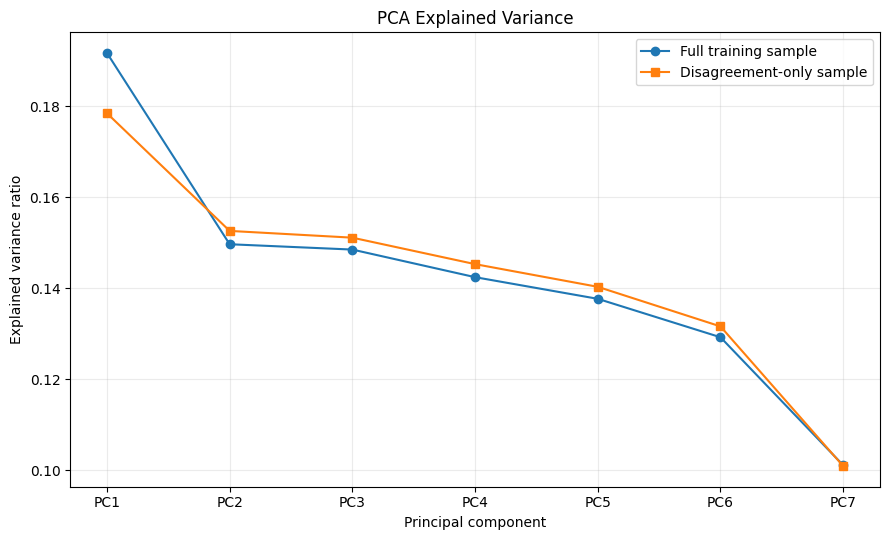

Saved to: C:\Users\USEO9DA\0_MyStuff\M2\results\figure1_pca_variance.png


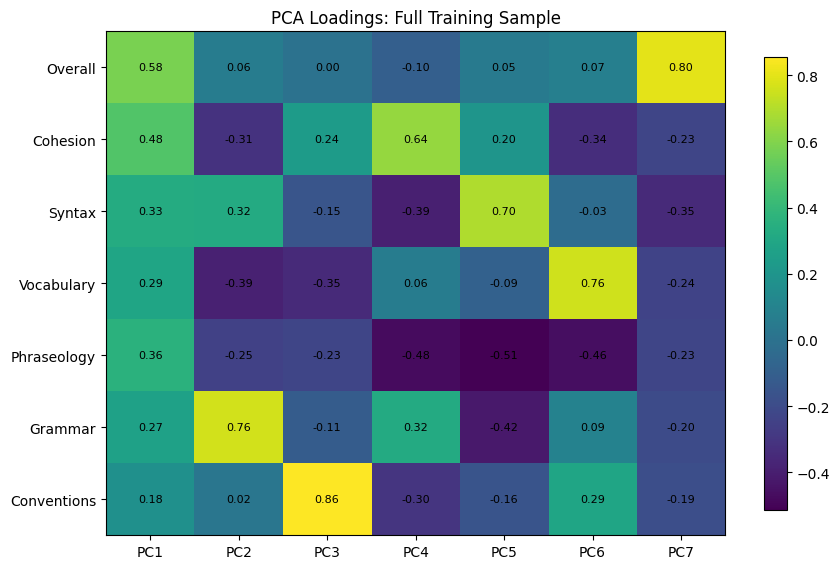

Saved to: C:\Users\USEO9DA\0_MyStuff\M2\results\figure2a_pca_loadings_full_sample.png


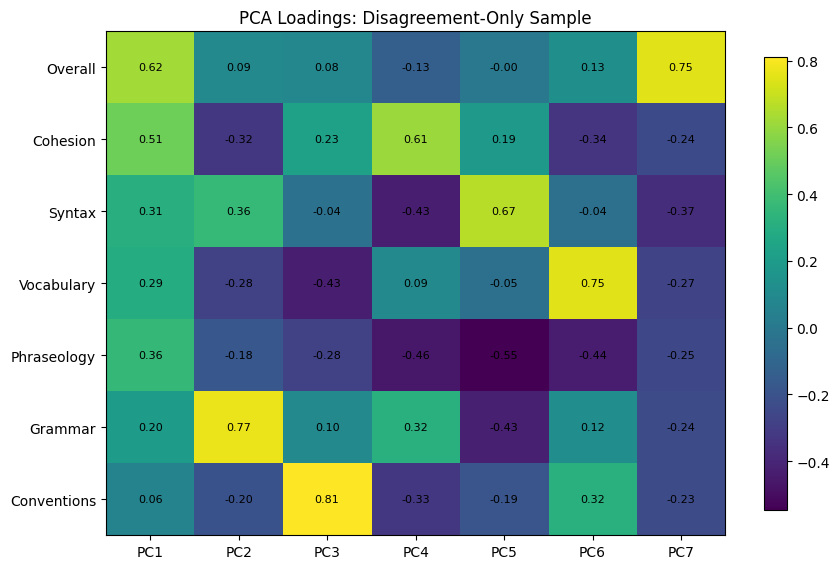

Saved to: C:\Users\USEO9DA\0_MyStuff\M2\results\figure2b_pca_loadings_disagreement_only_sample.png


In [8]:
# Figure 1: PCA explained variance for both feature representations
components = np.arange(1, len(DELTA_COLS) + 1)

plt.figure(figsize=(9, 5.5))
plt.plot(components,pca_full.explained_variance_ratio_,marker='o',label='Full training sample')
plt.plot(components,pca_disagree.explained_variance_ratio_,marker='s',label='Disagreement-only sample')
plt.xticks(components, [f'PC{i}' for i in components])
plt.xlabel('Principal component')
plt.ylabel('Explained variance ratio')
plt.title('PCA Explained Variance')
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
figure1_file = RESULTS_DIR / 'figure1_pca_variance.png'
plt.savefig(figure1_file, dpi=300, bbox_inches='tight')
plt.show()
print(f'Saved to: {figure1_file}')

# Figure 2A: PCA loadings for the full training sample
loading_values = pca_full_loadings.to_numpy()
row_labels = [c.replace('Delta_', '') for c in pca_full_loadings.index]
col_labels = list(pca_full_loadings.columns)
fig, ax = plt.subplots(figsize=(9, 5.8))
im = ax.imshow(loading_values, aspect='auto', cmap='viridis')
ax.set_xticks(np.arange(len(col_labels)))
ax.set_xticklabels(col_labels)
ax.set_yticks(np.arange(len(row_labels)))
ax.set_yticklabels(row_labels)
ax.set_title('PCA Loadings: Full Training Sample')
for i in range(loading_values.shape[0]):
    for j in range(loading_values.shape[1]):
        ax.text(j, i, f'{loading_values[i, j]:.2f}', ha='center', va='center', fontsize=8)
fig.colorbar(im, ax=ax, shrink=0.9)
plt.tight_layout()
figure2a_file = RESULTS_DIR / 'figure2a_pca_loadings_full_sample.png'
plt.savefig(figure2a_file, dpi=300, bbox_inches='tight')
plt.show()
print(f'Saved to: {figure2a_file}')

# Figure 2B: PCA loadings for the disagreement-only training sample
loading_values = pca_disagree_loadings.to_numpy()
row_labels = [c.replace('Delta_', '') for c in pca_disagree_loadings.index]
col_labels = list(pca_disagree_loadings.columns)
fig, ax = plt.subplots(figsize=(9, 5.8))
im = ax.imshow(loading_values,aspect='auto',cmap='viridis')
ax.set_xticks(np.arange(len(col_labels)))
ax.set_xticklabels(col_labels)
ax.set_yticks(np.arange(len(row_labels)))
ax.set_yticklabels(row_labels)
ax.set_title('PCA Loadings: Disagreement-Only Sample')
for i in range(loading_values.shape[0]):
    for j in range(loading_values.shape[1]):
        ax.text(j, i,f'{loading_values[i, j]:.2f}',ha='center',va='center',fontsize=8)
fig.colorbar(im, ax=ax, shrink=0.9)
plt.tight_layout()
figure2b_file = (RESULTS_DIR / 'figure2b_pca_loadings_disagreement_only_sample.png')
plt.savefig(figure2b_file,dpi=300,bbox_inches='tight')
plt.show()
print(f'Saved to: {figure2b_file}')

### Stage 4 Step 2: K-Means Evaluation and Visualizations

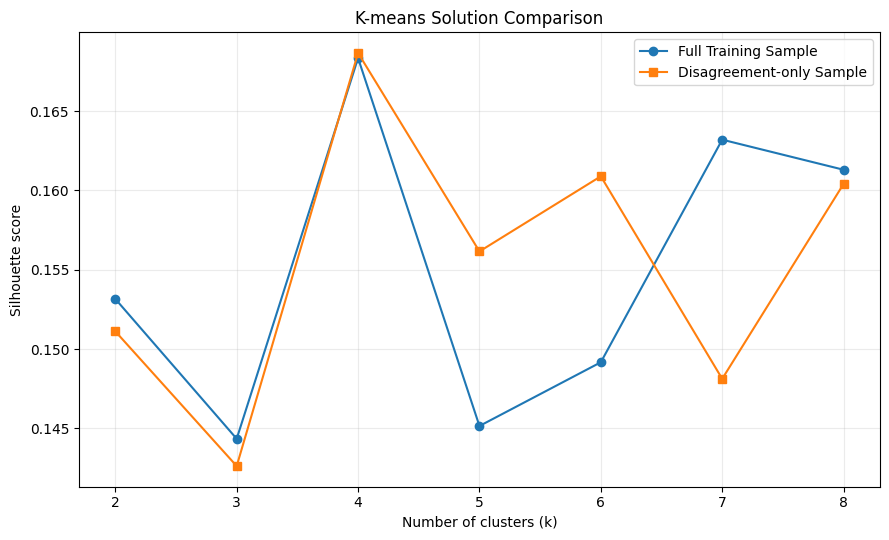

Saved to: C:\Users\USEO9DA\0_MyStuff\M2\results\figure3_silhouette.png


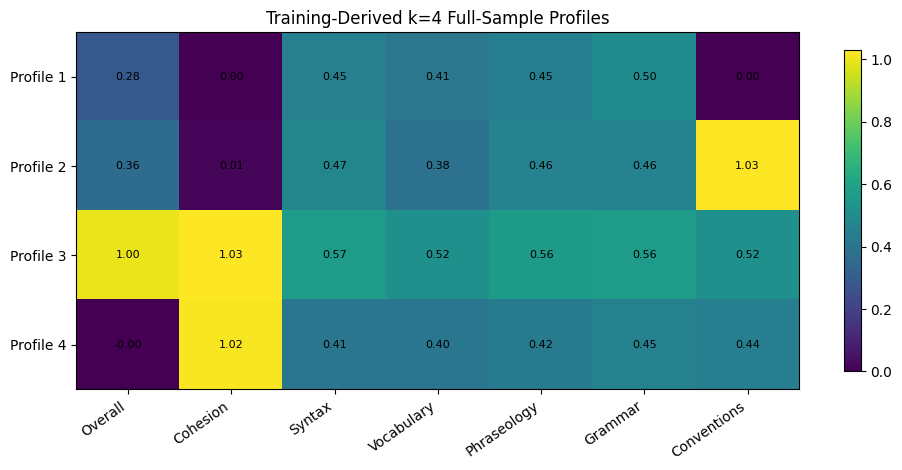

Saved to: C:\Users\USEO9DA\0_MyStuff\M2\results\figure4a_full_sample_centroid_heatmap.png


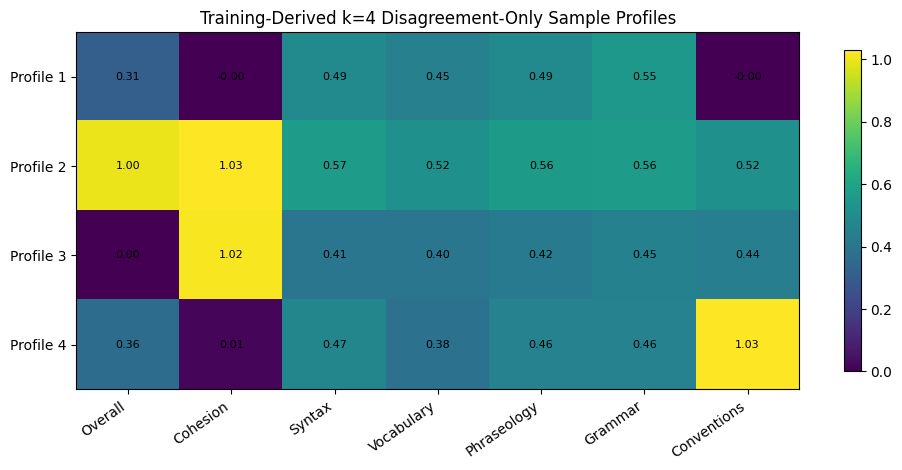

Saved to: C:\Users\USEO9DA\0_MyStuff\M2\results\figure4b_disagreementonly_centroid_heatmap.png


In [9]:
# Figure 3: Silhouette comparison across candidate K-means solutions
plt.figure(figsize=(9, 5.5))
plt.plot(full_kmeans_eval['k'],full_kmeans_eval['silhouette'],marker='o',label='Full Training Sample')
plt.plot(disagree_kmeans_eval['k'],disagree_kmeans_eval['silhouette'],marker='s',label='Disagreement-only Sample')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Silhouette score')
plt.title('K-means Solution Comparison')
plt.xticks(list(K_VALUES))
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
figure3_file = RESULTS_DIR / 'figure3_silhouette.png'
plt.savefig(figure3_file, dpi=300, bbox_inches='tight')
plt.show()
print(f'Saved to: {figure3_file}')

# Figure 4A: Training-derived full-sample k=4 centroid profiles
centroid_plot = (full_centroids.set_index('cluster')[DELTA_COLS].copy())
centroid_values = centroid_plot.to_numpy()
row_labels = [f'Profile {i}'for i in centroid_plot.index]
col_labels = [c.replace('Delta_', '')for c in centroid_plot.columns]
fig, ax = plt.subplots(figsize=(10, 4.8))
im = ax.imshow(centroid_values,aspect='auto',cmap='viridis')
ax.set_xticks(np.arange(len(col_labels)))
ax.set_xticklabels(col_labels,rotation=35,ha='right')
ax.set_yticks(np.arange(len(row_labels)))
ax.set_yticklabels(row_labels)
ax.set_title('Training-Derived k=4 Full-Sample Profiles')
for i in range(centroid_values.shape[0]):
    for j in range(centroid_values.shape[1]):
        ax.text(j, i,f'{centroid_values[i, j]:.2f}',ha='center',va='center',fontsize=8)
fig.colorbar(im, ax=ax, shrink=0.9)
plt.tight_layout()
figure4a_file = (RESULTS_DIR / 'figure4a_full_sample_centroid_heatmap.png')
plt.savefig(figure4a_file,dpi=300,bbox_inches='tight')
plt.show()
print(f'Saved to: {figure4a_file}')

# Figure 4B: Training-derived disagreement-only k=4 centroid profiles
centroid_plot = (disagree_centroids.set_index('cluster')[DELTA_COLS].copy())
centroid_values = centroid_plot.to_numpy()
row_labels = [f'Profile {i}' for i in centroid_plot.index]
col_labels = [c.replace('Delta_', '') for c in centroid_plot.columns]
fig, ax = plt.subplots(figsize=(10, 4.8))
im = ax.imshow(centroid_values, aspect='auto', cmap='viridis')
ax.set_xticks(np.arange(len(col_labels)))
ax.set_xticklabels(col_labels, rotation=35, ha='right')
ax.set_yticks(np.arange(len(row_labels)))
ax.set_yticklabels(row_labels)
ax.set_title('Training-Derived k=4 Disagreement-Only Sample Profiles')
for i in range(centroid_values.shape[0]):
    for j in range(centroid_values.shape[1]):
        ax.text(j, i, f'{centroid_values[i, j]:.2f}', ha='center', va='center', fontsize=8)
fig.colorbar(im, ax=ax, shrink=0.9)
plt.tight_layout()
figure4_file = RESULTS_DIR / 'figure4b_disagreementonly_centroid_heatmap.png'
plt.savefig(figure4_file, dpi=300, bbox_inches='tight')
plt.show()
print(f'Saved to: {figure4_file}')

### Stage 4 Step 3: K-Means Stability Summary and Visualization

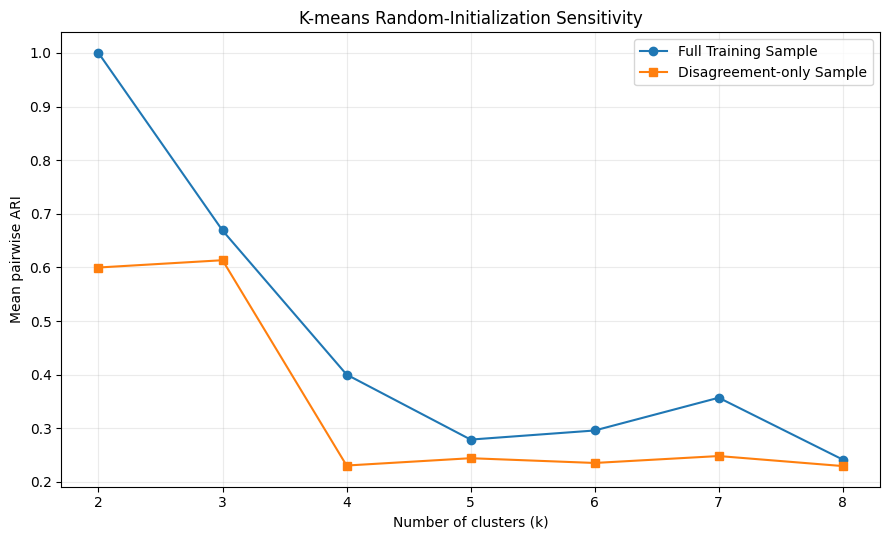

Saved to: C:\Users\USEO9DA\0_MyStuff\M2\results\figure5_kmeans_stability_ari.png


,sample,k,mean_pairwise_ARI,min_pairwise_ARI,max_pairwise_ARI,sd_pairwise_ARI
0,Full Training Sample,4,0.400,0.170,0.840,0.209
1,Disagreement-only Sample,4,0.231,0.088,0.629,0.149


Saved to: C:\Users\USEO9DA\0_MyStuff\M2\results\k4_stability_summary.csv


In [10]:
# Figure 5: Sensitivity visualization with mean pairwise ARI across random initializations
plt.figure(figsize=(9, 5.5))
plt.plot(full_stability['k'],full_stability['mean_pairwise_ARI'],marker='o',label='Full Training Sample')
plt.plot(disagree_stability['k'],disagree_stability['mean_pairwise_ARI'],marker='s',label='Disagreement-only Sample')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Mean pairwise ARI')
plt.title('K-means Random-Initialization Sensitivity')
plt.xticks(list(K_VALUES))
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()

# Saving the results 
sensitivity_file = RESULTS_DIR / 'figure5_kmeans_stability_ari.png'
plt.savefig(sensitivity_file, dpi=300, bbox_inches='tight')
plt.show()
print(f'Saved to: {sensitivity_file}')

k4_stability_summary = pd.concat([
    full_stability.loc[full_stability['k'] == 4].assign(sample='Full Training Sample'),
    disagree_stability.loc[disagree_stability['k'] == 4].assign(sample='Disagreement-only Sample')
], ignore_index=True)

# Displaying the selected k=4 stability results
display(k4_stability_summary[
        ['sample', 'k', 'mean_pairwise_ARI', 'min_pairwise_ARI',
         'max_pairwise_ARI', 'sd_pairwise_ARI']
    ].round(3))

# Saving the results 
output_file = RESULTS_DIR / 'k4_stability_summary.csv'
k4_stability_summary.to_csv(output_file,index=False)
print(f'Saved to: {output_file}')

# Stage 5: Holdout Replication of the Frozen Solution
- Do not refit PCA or K-means on holdout data.
- Apply the training-fitted transformations and centroids to the holdout sample to evaluate replication.

In [11]:
# Unsupervised Holdhout/Test Data Replication
# Part A: Full Sample Replication
holdout_pca_full = pca_full.transform(X_holdout_profile) # Applying the frozen training PCA
holdout_full_cluster = selected_full_km.predict(X_holdout_profile) # Assigning holdout essays into the frozen training K-means centroids

# A1. Compare training vs holdout cluster distributions
train_counts = (pd.Series(selected_full_km.labels_).value_counts().sort_index().rename('train_n'))
hold_counts = (pd.Series(holdout_full_cluster).value_counts().sort_index().rename('holdout_n'))
replication_sizes = (pd.concat([train_counts, hold_counts],axis=1).fillna(0))
replication_sizes['train_prop'] = (replication_sizes['train_n'] / replication_sizes['train_n'].sum())
replication_sizes['holdout_prop'] = (replication_sizes['holdout_n'] / replication_sizes['holdout_n'].sum())
replication_sizes['prop_difference'] = (replication_sizes['holdout_prop'] - replication_sizes['train_prop'])
replication_sizes.index.name = 'cluster'
replication_sizes = (replication_sizes.reset_index())
print('=' * 70)
print('Full Sampl: Train vs Holdhout Cluster Distribution')
print('=' * 70)
# Displaying the results
display(replication_sizes)

# A2. Frozen training centroids
training_full_centroids = pd.DataFrame(selected_full_km.cluster_centers_,columns=DELTA_COLS)
training_full_centroids.index.name = 'cluster'

# A3. Empirical holdout centroids
h_full = X_holdout_profile.copy()
h_full['cluster'] = holdout_full_cluster
holdout_full_centroids = (h_full.groupby('cluster')[DELTA_COLS].mean().reindex(range(SELECTED_K_FULL)))
holdout_full_centroids.index.name = 'cluster'

# A4. Training-vs-holdout centroid distances
centroid_rep = []
for c in training_full_centroids.index:
    if holdout_full_centroids.loc[c].isna().any():
        distance = np.nan
    else:
        distance = np.linalg.norm(training_full_centroids.loc[c, DELTA_COLS].to_numpy() - holdout_full_centroids.loc[c, DELTA_COLS].to_numpy())
    centroid_rep.append({'cluster': c,'euclidean_distance_train_vs_holdout_centroid':distance})
full_centroid_replication = pd.DataFrame(centroid_rep)
print('=' * 70)
print('Full Sample: Training Centroids')
print('=' * 70)
display(training_full_centroids)

print('=' * 70)
print('FULL SAMPLE — EMPIRICAL HOLDOUT CENTROIDS')
print('=' * 70)
display(holdout_full_centroids)

print('=' * 70)
print('FULL SAMPLE — CENTROID REPLICATION DISTANCES')
print('=' * 70)
display(full_centroid_replication)

# PART B: Disagreement-only Sample Replication
holdout_pca_disagree = pca_disagree.transform(X_holdout_disagree) # Applying frozen disagreement-only PCA
holdout_disagree_cluster = (selected_disagree_km.predict(X_holdout_disagree)) # Assigning holdout disagreement-only essays to frozen training-derived K-means centroids

# B1. Comparing training vs holdout cluster distributions
train_d = (pd.Series(selected_disagree_km.labels_).value_counts().sort_index().rename('train_n'))
hold_d = (pd.Series(holdout_disagree_cluster).value_counts().sort_index().rename('holdout_n'))
disagree_replication = (pd.concat([train_d, hold_d],axis=1).fillna(0))
disagree_replication['train_prop'] = (disagree_replication['train_n'] / disagree_replication['train_n'].sum())
disagree_replication['holdout_prop'] = (disagree_replication['holdout_n'] / disagree_replication['holdout_n'].sum())
disagree_replication['prop_difference'] = (disagree_replication['holdout_prop'] - disagree_replication['train_prop'])
disagree_replication.index.name = 'cluster'
disagree_replication = (disagree_replication.reset_index())
print('=' * 70)
print('Disagreement-only Sample: Train vs Holdout Distribution')
print('=' * 70)
display(disagree_replication)

# B2. Frozen training disagreement-only centroids
training_disagree_centroids = pd.DataFrame(selected_disagree_km.cluster_centers_,columns=DELTA_COLS)
training_disagree_centroids.index.name = 'cluster'

# B3. Empirical disagreement-only holdout centroids
h_disagree = X_holdout_disagree.copy()
h_disagree['cluster'] = (holdout_disagree_cluster)
holdout_disagree_centroids = (h_disagree.groupby('cluster')[DELTA_COLS].mean().reindex(range(SELECTED_K_DISAGREE)))
holdout_disagree_centroids.index.name = 'cluster'

# B4. Training-vs-holdout centroid distances
disagree_centroid_rep = []
for c in training_disagree_centroids.index:
    if holdout_disagree_centroids.loc[c].isna().any():
        distance = np.nan
    else:
        distance = np.linalg.norm(training_disagree_centroids.loc[c, DELTA_COLS].to_numpy() - holdout_disagree_centroids.loc[c, DELTA_COLS].to_numpy())
    disagree_centroid_rep.append({'cluster': c,'euclidean_distance_train_vs_holdout_centroid':distance})
disagree_centroid_replication = pd.DataFrame(disagree_centroid_rep)

print('=' * 70)
print('Disagreement-only Sample: Training Centroids')
print('=' * 70)
display(training_disagree_centroids)

print('=' * 70)
print('Disagreement-only Sample: Empirical Holdout Centroids')
print('=' * 70)
display(holdout_disagree_centroids)

print('=' * 70)
print('Disagreement-only Sample: Centroid Replication Distances')
print('=' * 70)
display(disagree_centroid_replication)


# PART C — SAVE ALL REPLICATION RESULTS
# C1. Full-sample cluster distribution
file_full_sizes = (RESULTS_DIR / 'unsupervised_full_train_holdout_cluster_distribution.csv')
replication_sizes.to_csv(file_full_sizes,index=False)

# C2. Full-sample training centroids
file_full_train_centroids = (RESULTS_DIR / 'unsupervised_full_training_centroids.csv')
training_full_centroids.reset_index().to_csv(file_full_train_centroids,index=False)

# C3. Full-sample holdout centroids
file_full_holdout_centroids = (RESULTS_DIR / 'unsupervised_full_holdout_centroids.csv')
holdout_full_centroids.reset_index().to_csv(file_full_holdout_centroids,index=False)

# C4. Full-sample centroid distances
file_full_distances = (RESULTS_DIR / 'unsupervised_full_centroid_replication_distances.csv')
full_centroid_replication.to_csv(file_full_distances,index=False)

# C5. Disagreement-only cluster distribution
file_disagree_sizes = (RESULTS_DIR / 'unsupervised_disagree_train_holdout_cluster_distribution.csv')
disagree_replication.to_csv(file_disagree_sizes,index=False)

# C6. Disagreement-only training centroids
file_disagree_train_centroids = (RESULTS_DIR / 'unsupervised_disagree_training_centroids.csv')
training_disagree_centroids.reset_index().to_csv(file_disagree_train_centroids,index=False)

# C7. Disagreement-only holdout centroids
file_disagree_holdout_centroids = (RESULTS_DIR / 'unsupervised_disagree_holdout_centroids.csv')
holdout_disagree_centroids.reset_index().to_csv(file_disagree_holdout_centroids, index=False)

# C8. Disagreement-only centroid distances
file_disagree_distances = (RESULTS_DIR / 'unsupervised_disagree_centroid_replication_distances.csv')
disagree_centroid_replication.to_csv(file_disagree_distances,index=False)

# PART D — SAVE HOLDOUT CLUSTER ASSIGNMENTS
# Saving row ID + full-sample cluster assignment
holdout_full_assignments = pd.DataFrame({'main_row_id': holdout_df['main_row_id'].values,'full_kmeans_cluster': holdout_full_cluster})
file_full_assignments = (RESULTS_DIR / 'full_holdout_cluster_assignments.csv')
holdout_full_assignments.to_csv(file_full_assignments,index=False)
# Saving row ID + disagreement-only cluster assignment
holdout_disagree_assignments = pd.DataFrame({'main_row_id': holdout_df.loc[X_holdout_disagree.index,'main_row_id'].values,'disagree_kmeans_cluster': holdout_disagree_cluster})
file_disagree_assignments = (RESULTS_DIR / 'disagree_holdout_cluster_assignments.csv')
holdout_disagree_assignments.to_csv(file_disagree_assignments,index=False)

# Saving confirmation
print('=' * 70)
print('Unsupervided Holdout/Test Replication Files Saved')
print('=' * 70)
saved_files = [file_full_sizes,file_full_train_centroids,file_full_holdout_centroids,file_full_distances,
    file_disagree_sizes,file_disagree_train_centroids,file_disagree_holdout_centroids,file_disagree_distances,
    file_full_assignments,file_disagree_assignments]
for f in saved_files:
    print(f)

Full Sampl: Train vs Holdhout Cluster Distribution


,cluster,train_n,holdout_n,train_prop,holdout_prop,prop_difference
0,0,969,690,0.276068,0.296137,0.020069
1,1,801,544,0.228205,0.233476,0.005271
2,2,816,521,0.232479,0.223605,-0.008873
3,3,924,575,0.263248,0.246781,-0.016467


Full Sample: Training Centroids


,Delta_Overall,Delta_Cohesion,Delta_Syntax,Delta_Vocabulary,Delta_Phraseology,Delta_Grammar,Delta_Conventions
cluster,,,,,,,
0,2.837977e-01,5.551115e-16,0.448916,0.408669,0.445820,0.499484,1.110223e-16
1,3.632959e-01,1.248439e-02,0.471910,0.383271,0.455680,0.456929,1.028714e+00
2,1.001225e+00,1.029412e+00,0.568627,0.515931,0.560049,0.564951,5.183824e-01
3,-3.330669e-16,1.018398e+00,0.405844,0.403680,0.418831,0.453463,4.404762e-01


FULL SAMPLE — EMPIRICAL HOLDOUT CENTROIDS


...

Disagreement-only Sample: Empirical Holdout Centroids


,Delta_Overall,Delta_Cohesion,Delta_Syntax,Delta_Vocabulary,Delta_Phraseology,Delta_Grammar,Delta_Conventions
cluster,,,,,,,
0,0.318110,0.000000,0.492913,0.478740,0.521260,0.494488,0.000000
1,1.001919,1.023033,0.537428,0.522073,0.619962,0.535509,0.579655
2,0.000000,1.017391,0.415652,0.380870,0.403478,0.478261,0.462609
3,0.330882,0.011029,0.437500,0.395221,0.457721,0.522059,1.020221


Disagreement-only Sample: Centroid Replication Distances


,cluster,euclidean_distance_train_vs_holdout_centroid
0,0,0.069783
1,1,0.096244
2,2,0.044249
3,3,0.081840


Unsupervided Holdout/Test Replication Files Saved
C:\Users\USEO9DA\0_MyStuff\M2\results\unsupervised_full_train_holdout_cluster_distribution.csv
C:\Users\USEO9DA\0_MyStuff\M2\results\unsupervised_full_training_centroids.csv
C:\Users\USEO9DA\0_MyStuff\M2\results\unsupervised_full_holdout_centroids.csv
C:\Users\USEO9DA\0_MyStuff\M2\results\unsupervised_full_centroid_replication_distances.csv
C:\Users\USEO9DA\0_MyStuff\M2\results\unsupervised_disagree_train_holdout_cluster_distribution.csv
C:\Users\USEO9DA\0_MyStuff\M2\results\unsupervised_disagree_training_centroids.csv
C:\Users\USEO9DA\0_MyStuff\M2\results\unsupervised_disagree_holdout_centroids.csv
C:\Users\USEO9DA\0_MyStuff\M2\results\unsupervised_disagree_centroid_replication_distances.csv
C:\Users\USEO9DA\0_MyStuff\M2\results\full_holdout_cluster_assignments.csv
C:\Users\USEO9DA\0_MyStuff\M2\results\disagree_holdout_cluster_assignments.csv


# Additional Exploratory Analysis: Rater-Pair Association With Profile Membership
- This analysis examines whether the **type of disagreement profile** differs across unordered rater-pair configurations.
- The previously selected **four-profile K-means solution is kept fixed**.
- The association is examined first in the training sample and then evaluated again in the holdout sample for replication.
- Evaluation Metrics:
    - **Chi-square test**: Checks whether rater pairs and disagreement profiles are related.
    - **Cramer's V**: Shows how strong the relationship is.
    - **Permutation test**: Double-checks the significance because some cell counts are small.
    - **Standardized residuals**: Shows which specific rater-pair and profile combinations occur more or less often than expected.

In [12]:
# Additional Analysis: Association between unordered rater pair and frozen disagreement profile
# Importing function for chi-square association
from scipy.stats import chi2_contingency
# Creating unordered rater-pair identifiers
def make_unordered_rater_pair(data):
    r1 = data['Rater_1'].fillna('__MISSING__').astype(str)
    r2 = data['Rater_2'].fillna('__MISSING__').astype(str)
    return pd.Series([f'{a}||{b}' if a <= b else f'{b}||{a}' for a, b in zip(r1, r2)],index=data.index,name='rater_pair')

# Rater-Pair and Disagreement-Profile Association Analysis 
    # with Permutation Testing and Standardized Residuals
    # Use 2,000 permutations for stable empirical p-value with keeping computation manageable
def rater_pair_profile_association(data, profiles, sample_name, n_permutations=2000):
    analysis_df = data.copy()
    analysis_df['rater_pair'] = make_unordered_rater_pair(analysis_df)
    analysis_df['profile'] = np.asarray(profiles, dtype=int)
    counts = pd.crosstab(analysis_df['rater_pair'], analysis_df['profile']) # Building rater-pair × profile contingency table
    counts = counts.reindex(columns=[1, 2, 3, 4], fill_value=0)
    observed = counts.to_numpy() # Converting contingency table to observed frequency counts
    chi2, p_value, dof, expected = chi2_contingency(observed)  # Calculating expected frequencies under no association
    n = observed.sum()                                         # Measureing the strength using cramers_v 
    r, c = observed.shape
    cramers_v = np.sqrt(chi2 / (n * min(r - 1, c - 1))) 
    expected_lt_5 = int((expected < 5).sum()) # Check how many expected cell counts are below 5
    expected_total = int(expected.size)
    # Permutation test retains rater-pair membership and shuffles profile labels        
    rng = np.random.default_rng(RANDOM_STATE)           # Running 2,000 permutations for robust significance checking 
    pair_vector = analysis_df['rater_pair'].to_numpy()  
    profile_vector = analysis_df['profile'].to_numpy()
    permuted_stats = np.empty(n_permutations)
    for i in range(n_permutations):
        shuffled = rng.permutation(profile_vector)
        perm_table = pd.crosstab(pair_vector, shuffled).reindex(columns=[1, 2, 3, 4], fill_value=0)
        permuted_stats[i] = chi2_contingency(perm_table.to_numpy())[0]
    permutation_p = (1 + np.sum(permuted_stats >= chi2)) / (n_permutations + 1) # calculating permutation p-value
    # Summarizing overall association results
    summary = pd.DataFrame([{'sample': sample_name,
        'n_essays': n,
        'n_rater_pairs': analysis_df['rater_pair'].nunique(),
        'chi_square': chi2,
        'df': dof,
        'chi_square_p': p_value,
        'cramers_v': cramers_v,
        'expected_cells_lt_5': expected_lt_5,
        'expected_cells_total': expected_total,
        'expected_cells_lt_5_prop': expected_lt_5 / expected_total,
        'n_permutations': n_permutations,
        'permutation_p': permutation_p}])
    expected_df = pd.DataFrame(expected, index=counts.index, columns=counts.columns) # Standardized residuals
    standardized_residuals = (counts - expected_df) / np.sqrt(expected_df)  # Computing standardized residuals for each cell
    pair_n = counts.sum(axis=1)            
    standardized_residuals['Total_n'] = pair_n  # Limiting residual analysis at least 20 essays
    residual_long = (standardized_residuals.loc[standardized_residuals['Total_n'] >= 20].drop(columns='Total_n')
        .reset_index().melt(id_vars='rater_pair', var_name='profile', value_name='standardized_residual'))
    # Identify notable combinations
    residual_long['abs_residual'] = residual_long['standardized_residual'].abs()
    notable = residual_long.loc[residual_long['abs_residual'] >= 2].sort_values('abs_residual', ascending=False).reset_index(drop=True)
    return summary, counts, standardized_residuals, notable

# Training: frozen k=4 profile labels
train_profile_df = train_df.loc[X_train_disagree.index].copy()
train_profiles = selected_disagree_km.labels_ + 1

# Holdout: frozen training-derived profile assignments
holdout_profile_df = holdout_df.loc[X_holdout_disagree.index].copy()
holdout_profiles = holdout_disagree_cluster + 1
train_assoc, train_pair_profile_counts, train_residuals, train_notable = (rater_pair_profile_association(train_profile_df,train_profiles,'Training',n_permutations=2000))
holdout_assoc, holdout_pair_profile_counts, holdout_residuals, holdout_notable = (rater_pair_profile_association(holdout_profile_df,holdout_profiles,'Holdout',n_permutations=2000))
association_summary = pd.concat([train_assoc, holdout_assoc], ignore_index=True)
print('=' * 50)
print('Rater-Pair and Profile Association Summary')
print('=' * 50)
# Displaying the results
display(association_summary.round({
    'chi_square': 3,
    'chi_square_p': 4,
    'cramers_v': 3,
    'expected_cells_lt_5_prop': 3,
    'permutation_p': 4}))

print('=' * 80)
print('Training Notable Pair-Profile Cells (|standardized residual| >= 2; pair n >= 20):')
print('=' * 80)
display(train_notable)

# Saving additional analysis results
output_file = RESULTS_DIR / 'additional_raterpair_profile_association_summary.csv'
association_summary.to_csv(output_file, index=False)
print(f'Saved to: {output_file}')
output_file = RESULTS_DIR / 'additional_raterpair_profile_train_counts.csv'
train_pair_profile_counts.reset_index().to_csv(output_file,index=False)
print(f'Saved to: {output_file}')
output_file = RESULTS_DIR / 'addional_raterpair_profile_holdout_counts.csv'
holdout_pair_profile_counts.reset_index().to_csv(output_file,index=False)
print(f'Saved to: {output_file}')
output_file = RESULTS_DIR / 'addional_raterpair_profile_train_standardized_residuals.csv'
train_residuals.reset_index().to_csv(output_file,index=False)
print(f'Saved to: {output_file}')
output_file = RESULTS_DIR / 'addional_raterpair_profile_train_notable_associations.csv'
train_notable.to_csv(output_file,index=False)
print(f'Saved to: {output_file}')

Rater-Pair and Profile Association Summary


,sample,n_essays,n_rater_pairs,chi_square,df,chi_square_p,cramers_v,expected_cells_lt_5,expected_cells_total,expected_cells_lt_5_prop,n_permutations,permutation_p
0,Training,3425,72,279.817,213,0.0014,0.165,124,288,0.431,2000,0.001
1,Holdout,2275,72,270.041,213,0.0049,0.199,138,288,0.479,2000,0.002


Training Notable Pair-Profile Cells (|standardized residual| >= 2; pair n >= 20):


,rater_pair,profile,standardized_residual,abs_residual
0,rater_12||rater_19,4,2.928294,2.928294
1,rater_12||rater_15,1,-2.559548,2.559548
2,rater_11||rater_8,1,2.526385,2.526385
3,rater_15||rater_19,2,-2.500669,2.500669
4,rater_5||rater_6,2,-2.447321,2.447321
5,rater_2||rater_4,1,-2.439175,2.439175
6,rater_1||rater_2,2,2.390723,2.390723
7,rater_12||rater_13,3,-2.326897,2.326897
8,rater_2||rater_7,1,-2.263289,2.263289
9,rater_15||rater_19,3,2.105998,2.105998


Saved to: C:\Users\USEO9DA\0_MyStuff\M2\results\additional_raterpair_profile_association_summary.csv
Saved to: C:\Users\USEO9DA\0_MyStuff\M2\results\additional_raterpair_profile_train_counts.csv
Saved to: C:\Users\USEO9DA\0_MyStuff\M2\results\addional_raterpair_profile_holdout_counts.csv
Saved to: C:\Users\USEO9DA\0_MyStuff\M2\results\addional_raterpair_profile_train_standardized_residuals.csv
Saved to: C:\Users\USEO9DA\0_MyStuff\M2\results\addional_raterpair_profile_train_notable_associations.csv


# End of Unsupervised Analysis
